<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp10_EM_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 10: Expectation-Maximization (EM) Algorithm
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a Python program to implement the Expectation & Maximization algorithm.

## Background
EM fits models with hidden (latent) variables. For a **Gaussian Mixture Model (GMM)** the hidden variable is *which component generated each point*.

* **E-step:** compute responsibilities `r_ik = pi_k N(x_i | mu_k, Sigma_k) / sum_j pi_j N(x_i | mu_j, Sigma_j)`
* **M-step:** re-estimate `pi_k = N_k / N`, `mu_k = sum r_ik x_i / N_k`, `Sigma_k = sum r_ik (x_i - mu_k)(x_i - mu_k)^T / N_k`

Each iteration is guaranteed not to decrease the data log-likelihood.



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We sample 900 points in 2-D from **three known Gaussians**. Because we know the true parameters, we can later check how well EM recovers them. The hidden component label is saved separately for evaluation only - EM never sees it.

In [2]:
rng = np.random.RandomState(42)
true_weights = np.array([0.30, 0.45, 0.25])
true_means = np.array([[0.0, 0.0], [5.0, 4.0], [-1.0, 6.0]])
true_covs = np.array([[[1.0, 0.3], [0.3, 0.8]],
                      [[1.5, -0.6], [-0.6, 1.0]],
                      [[0.7, 0.0], [0.0, 1.4]]])
n = 900
component = rng.choice(3, size=n, p=true_weights)
points = np.array([rng.multivariate_normal(true_means[c], true_covs[c]) for c in component])

pd.DataFrame({"x1": points[:, 0], "x2": points[:, 1], "true_component": component}).to_csv("gmm_data.csv", index=False)
print("Saved gmm_data.csv")

Saved gmm_data.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("gmm_data.csv")
df.head()

,x1,x2,true_component
0,4.088393,3.443015,1
1,-1.154700,7.093324,2
2,6.050239,4.276415,1
3,5.202641,2.553700,1
4,1.121920,1.379391,0


## Step 3: Data Preprocessing
EM needs only the numeric features. The true labels are kept aside for evaluation.

In [4]:
print("Missing values:", df.isnull().sum().sum())
X = df[["x1", "x2"]].values
true_labels = df["true_component"].values
print("X shape:", X.shape)

Missing values: 0
X shape: (900, 2)


## Step 4: Exploratory Data Analysis (EDA)

    count      mean       std       min       25%       50%       75%  \
x1  900.0  1.934583  2.947606 -3.444177 -0.656580  0.830682  4.813502   
x2  900.0  3.318929  2.533754 -2.438736  0.808652  3.852434  5.153388   

         max  
x1  8.850921  
x2  9.029133  


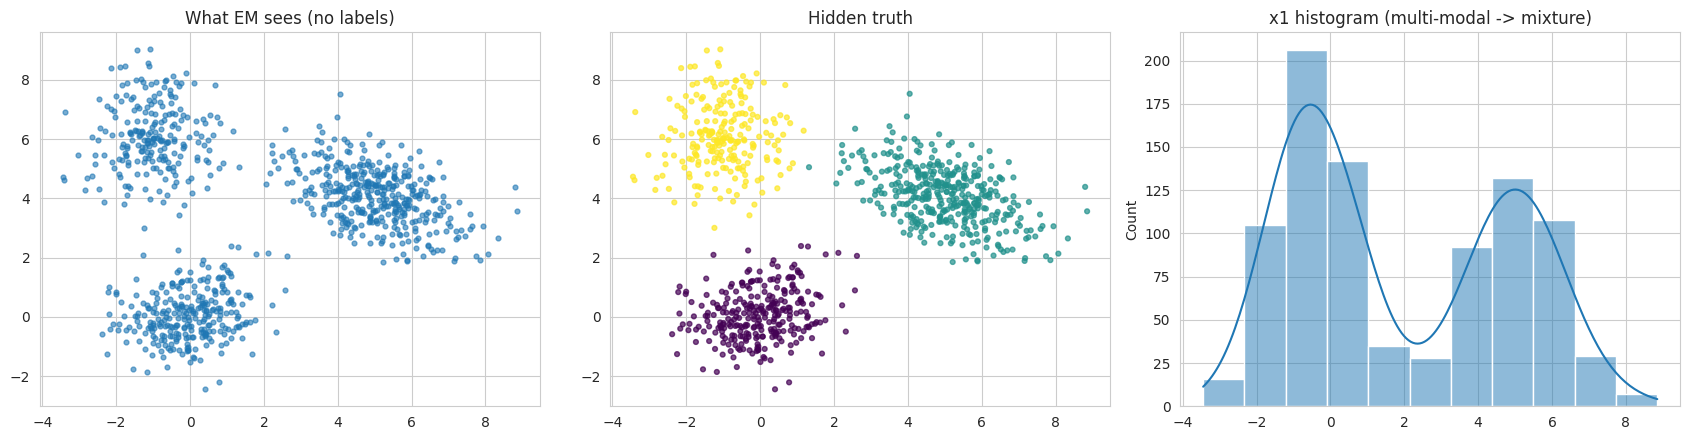

In [5]:
print(df[["x1", "x2"]].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], s=12, alpha=.6); axes[0].set_title("What EM sees (no labels)")
axes[1].scatter(X[:, 0], X[:, 1], c=true_labels, cmap="viridis", s=12, alpha=.7); axes[1].set_title("Hidden truth")
sns.histplot(X[:, 0], kde=True, ax=axes[2]); axes[2].set_title("x1 histogram (multi-modal -> mixture)")
plt.tight_layout(); plt.show()

## Step 5: Model Training (EM from scratch)
Implementation of EM for a K-component GMM. Means are initialised with K-means (standard practice) and a small ridge keeps covariances invertible.

EM converged after 6 iterations; final log-likelihood = -3452.57


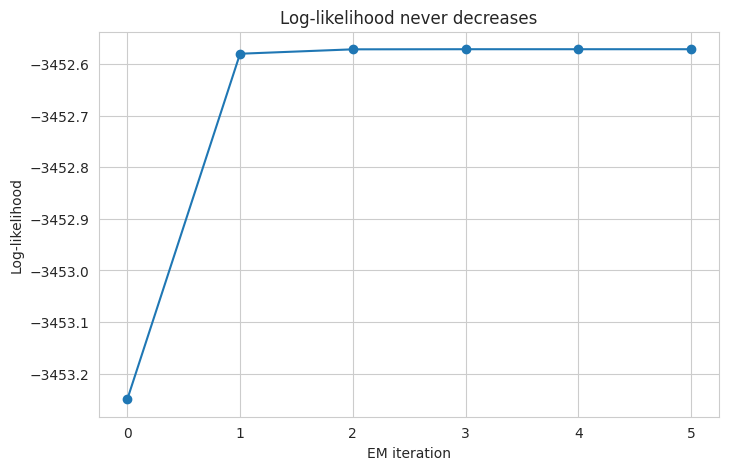

Monotonic increase: True


In [6]:
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans

def em_gmm(X, K, max_iter=300, tol=1e-6, reg=1e-6, seed=42):
    n, d = X.shape
    km = KMeans(n_clusters=K, n_init=10, random_state=seed).fit(X)
    mu = km.cluster_centers_.copy()
    cov = np.array([np.cov(X[km.labels_ == k].T) + reg * np.eye(d) for k in range(K)])
    pi = np.array([(km.labels_ == k).mean() for k in range(K)])
    log_likelihoods = []
    for it in range(max_iter):
        # ---- E-step: responsibilities ----
        dens = np.column_stack([pi[k] * multivariate_normal.pdf(X, mu[k], cov[k]) for k in range(K)])
        ll = np.log(dens.sum(axis=1)).sum()
        resp = dens / dens.sum(axis=1, keepdims=True)
        log_likelihoods.append(ll)
        # ---- M-step: update parameters ----
        Nk = resp.sum(axis=0)
        pi = Nk / n
        mu = (resp.T @ X) / Nk[:, None]
        for k in range(K):
            diff = X - mu[k]
            cov[k] = (resp[:, k, None] * diff).T @ diff / Nk[k] + reg * np.eye(d)
        if it > 0 and abs(log_likelihoods[-1] - log_likelihoods[-2]) < tol:
            break
    return {"pi": pi, "mu": mu, "cov": cov, "resp": resp, "ll": log_likelihoods, "iters": it + 1}

def responsibilities(X, params):
    dens = np.column_stack([params["pi"][k] * multivariate_normal.pdf(X, params["mu"][k], params["cov"][k])
                            for k in range(len(params["pi"]))])
    return dens / dens.sum(axis=1, keepdims=True)

gmm = em_gmm(X, K=3)
print("EM converged after", gmm["iters"], "iterations; final log-likelihood =", round(gmm["ll"][-1], 2))

plt.plot(gmm["ll"], marker="o"); plt.xlabel("EM iteration"); plt.ylabel("Log-likelihood")
plt.title("Log-likelihood never decreases"); plt.show()
print("Monotonic increase:", all(np.diff(gmm["ll"]) >= -1e-8))

## Step 6: Model Evaluation
1) Compare recovered parameters with the truth. 2) Clustering quality (Adjusted Rand Index) vs hidden labels. 3) Compare with scikit-learn's `GaussianMixture`. 4) Use BIC to see whether K=3 is the best number of components.

In [7]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score, confusion_matrix
from sklearn.mixture import GaussianMixture

# match learned components to true components (component order is arbitrary)
cost = np.linalg.norm(gmm["mu"][:, None] - true_means[None], axis=2)
row, col = linear_sum_assignment(cost)
order = row[np.argsort(col)]
print("Mixing weights  true:", true_weights, " learned:", gmm["pi"][order].round(3))
print("Means (learned):\n", gmm["mu"][order].round(2), "\nMeans (true):\n", true_means)

pred = gmm["resp"].argmax(axis=1)
print("\nAdjusted Rand Index vs hidden labels (scratch EM):", round(adjusted_rand_score(true_labels, pred), 4))

sk = GaussianMixture(n_components=3, random_state=42, n_init=5).fit(X)
print("Adjusted Rand Index (sklearn GMM)               :", round(adjusted_rand_score(true_labels, sk.predict(X)), 4))
print("Avg log-likelihood per sample  scratch:", round(gmm["ll"][-1] / len(X), 4), "| sklearn:", round(sk.score(X), 4))

Mixing weights  true: [0.3  0.45 0.25]  learned: [0.314 0.438 0.248]
Means (learned):
 [[-0.04  0.08]
 [ 5.03  4.08]
 [-1.01  6.08]] 
Means (true):
 [[ 0.  0.]
 [ 5.  4.]
 [-1.  6.]]

Adjusted Rand Index vs hidden labels (scratch EM): 0.9967
Adjusted Rand Index (sklearn GMM)               : 0.9967
Avg log-likelihood per sample  scratch: -3.8362 | sklearn: -3.8362


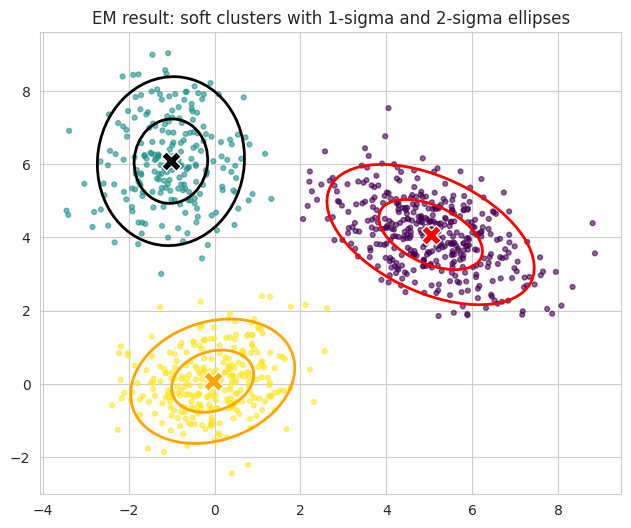

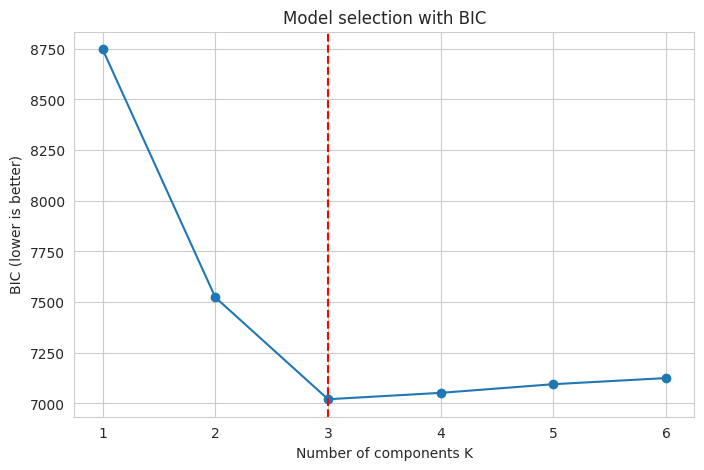

K with the lowest BIC: 3


In [8]:
from matplotlib.patches import Ellipse

def draw_ellipse(ax, mean, cov, color):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    for ns in (1, 2):
        ax.add_patch(Ellipse(mean, 2 * ns * np.sqrt(vals[1]), 2 * ns * np.sqrt(vals[0]), angle=angle,
                             fill=False, edgecolor=color, linewidth=2))

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(X[:, 0], X[:, 1], c=pred, cmap="viridis", s=12, alpha=.6)
for k, color in enumerate(["red", "black", "orange"]):
    draw_ellipse(ax, gmm["mu"][k], gmm["cov"][k], color)
    ax.scatter(*gmm["mu"][k], marker="X", s=200, color=color, edgecolor="white")
ax.set_title("EM result: soft clusters with 1-sigma and 2-sigma ellipses"); plt.show()

ks = range(1, 7)
bics = [GaussianMixture(k, random_state=42, n_init=3).fit(X).bic(X) for k in ks]
plt.plot(ks, bics, marker="o"); plt.axvline(list(ks)[int(np.argmin(bics))], color="r", linestyle="--")
plt.xlabel("Number of components K"); plt.ylabel("BIC (lower is better)"); plt.title("Model selection with BIC"); plt.show()
print("K with the lowest BIC:", list(ks)[int(np.argmin(bics))])

## Step 7: Prediction on New Data
Soft-assign new points to the learned components using the responsibilities.

In [9]:
new_points = np.array([[0.2, 0.1], [5.0, 4.5], [-1.0, 6.5], [2.5, 2.5]])
probs = responsibilities(new_points, gmm)
for p, r in zip(new_points, probs):
    print(f"Point {p} -> responsibilities = {r.round(3)} -> component {r.argmax()}")

Point [0.2 0.1] -> responsibilities = [0. 0. 1.] -> component 2
Point [5.  4.5] -> responsibilities = [1. 0. 0.] -> component 0
Point [-1.   6.5] -> responsibilities = [0. 1. 0.] -> component 1
Point [2.5 2.5] -> responsibilities = [0.422 0.    0.578] -> component 2


## Conclusion
EM converged in only a handful of iterations (K-means initialisation gives it a strong start) with the log-likelihood increasing monotonically. It recovered the true weights, means and covariances closely, matched scikit-learn's GMM (Adjusted Rand Index about 0.99), and BIC correctly preferred K = 3. Points between clusters (like [2.5, 2.5]) receive *soft* assignments, an advantage over K-means. EM can reach only a local optimum, so good initialisation matters.